In [2]:
import sys
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from scipy import stats
    SCIPY_AVAILABLE = True
except Exception:
    SCIPY_AVAILABLE = False

In [3]:
PROJECT_ROOT = Path.home()
DATA_PATH = PROJECT_ROOT / 'presentation' / 'logistics_shipments_dataset.csv'
OUTPUT_DIR = PROJECT_ROOT / 'presentation'/ 'output'
FIGURE_DIR = PROJECT_ROOT / 'presentation' /'fingures'
OUTPUT_DIR.mkdir(exist_ok=True)
print('Dataset exists:', DATA_PATH.exists())
print('Output folder:', OUTPUT_DIR.resolve())

Dataset exists: True
Output folder: /home/jovyan/presentation/output


In [4]:
df_raw = pd.read_csv(DATA_PATH)

In [5]:
df_raw.head()

,Shipment_ID,Origin_Warehouse,Destination,Carrier,Shipment_Date,Delivery_Date,Weight_kg,Cost,Status,Distance_miles,Transit_Days
0,SH10000,Warehouse_MIA,San Francisco,UPS,2023-10-02,2023-10-04,25.7,67.46,Delivered,291,2
1,SH10001,Warehouse_MIA,Atlanta,DHL,2023-12-06,2023-12-09,38.9,268.85,Delivered,1225,3
2,SH10002,Warehouse_LA,Houston,DHL,2023-09-18,2023-09-20,37.2,74.35,Delivered,220,2
3,SH10003,Warehouse_BOS,Seattle,OnTrac,2023-01-26,2023-02-04,42.6,187.04,Delivered,1156,9
4,SH10004,Warehouse_SF,Dallas,OnTrac,2023-06-03,2023-06-06,7.9,120.01,Delivered,1017,3


In [6]:
categorical = ['Shipment_ID','Origin_Warehouse','Destination','Carrier','Status']
date = ['Shipment_Date', 'Delivery_Date']
numeric = ['Weight_kg', 'Cost', 'Distance_miles', 'Transit_Days']

In [7]:
audit = pd.DataFrame({
    'dtype': df_raw.dtypes.astype(str),
    'missing_count': df_raw.isna().sum(),
    'missing_percent': (df_raw.isna().mean() * 100).round(1),
    'unique_values': df_raw.nunique(dropna=True),
    'min_value': df_raw[numeric].min().astype(str),
    'max_value': df_raw[numeric].max().astype(str)
})

audit

,dtype,missing_count,missing_percent,unique_values,min_value,max_value
Carrier,str,0,0.0,7,NaN,NaN
Cost,float64,41,2.1,1903,17.89,6562.21
Delivery_Date,str,32,1.6,368,NaN,NaN
Destination,str,0,0.0,15,NaN,NaN
Distance_miles,int64,0,0.0,1309,101.0,2499.0
Origin_Warehouse,str,0,0.0,10,NaN,NaN
Shipment_Date,str,0,0.0,364,NaN,NaN
Shipment_ID,str,0,0.0,2000,NaN,NaN
Status,str,0,0.0,5,NaN,NaN
Transit_Days,int64,0,0.0,12,1.0,12.0


In [8]:
duplicate_count = df_raw.duplicated().sum()
print('Exact duplicate rows:', duplicate_count)

Exact duplicate rows: 0


In [9]:
Status_before = sorted(df_raw['Status'].dropna().unique())
Status_before

['Delayed', 'Delivered', 'In Transit', 'Lost', 'Returned']

In [10]:
Carrier_before = sorted(df_raw['Carrier'].dropna().unique())
Carrier_before

['Amazon Logistics', 'DHL', 'FedEx', 'LaserShip', 'OnTrac', 'UPS', 'USPS']

impossible or suspicious numeric values

In [11]:
df_clean = df_raw.copy()

In [12]:
cleaning_log = []
median_values = df_clean[numeric].median()
median_values

Weight_kg           20.70
Cost               196.42
Distance_miles    1262.50
Transit_Days         4.00
dtype: float64

fill missing numeric values

In [13]:
   for col in numeric:
    median_value = median_values[col]
    df_clean[col] = df_clean[col].fillna(median_value)

In [14]:
verification = pd.DataFrame({
    'raw_missing': df_raw.isna().sum(),
    'clean_missing': df_clean.isna().sum(),
})

verification

,raw_missing,clean_missing
Shipment_ID,0,0
Origin_Warehouse,0,0
Destination,0,0
Carrier,0,0
Shipment_Date,0,0
Delivery_Date,32,32
Weight_kg,0,0
Cost,41,0
Status,0,0
Distance_miles,0,0


In [15]:
def plot_boxplot(data, column):
    ax = data.boxplot(column=column)
    ax.set_title(f'Boxplot: {column}')
    plt.show()

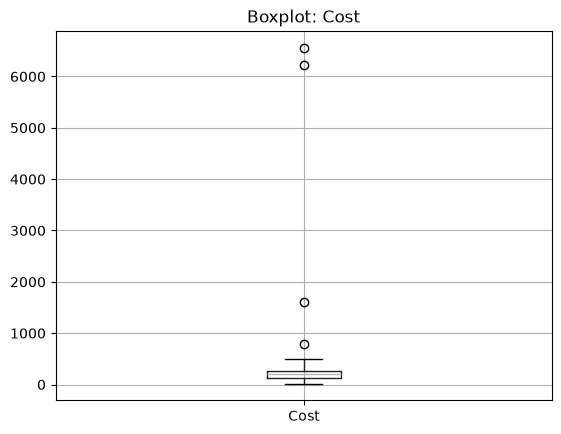

In [16]:
vidualize_columns = [ 'Cost']
for column in vidualize_columns:
    plot_boxplot(df_raw, column)

detect candidate outliers using median absolute deviation (MAD)

In [17]:
def mad_outliers(data, column, threshold=3.5):
    values = data[column]
    median = values.median()
    mad = (values - median).abs().median()

    if mad == 0 or pd.isna(mad):
        return pd.DataFrame(columns=[
            'Shipment_ID',
            column,
            'modified_z_score',
            'median',
            'mad',
        ])

    modified_z_scores = 0.6745 * (values - median) / mad
    mask = modified_z_scores.abs() > threshold

    result = data.loc[mask, ['Shipment_ID', column]].copy()
    result['modified_z_score'] = modified_z_scores.loc[mask].round(2)
    result['median'] = round(median, 2)
    result['mad'] = round(mad, 2)
    return result.sort_values(
        'modified_z_score',
        key=lambda s: s.abs(),
        ascending=False,
    )

In [18]:
focus_columns=['Cost']
for column in focus_columns:
    print(f'MAD outliers for {column}')
    display(mad_outliers(df_clean, column, threshold=3.5).round(2))
    

MAD outliers for Cost


,Shipment_ID,Cost,modified_z_score,median,mad
1105,SH11105,6562.21,56.54,196.42,75.94
922,SH10922,6229.12,53.58,196.42,75.94
1912,SH11912,1597.99,12.45,196.42,75.94
1149,SH11149,782.71,5.21,196.42,75.94


In [19]:
df_olf = df_clean.copy()

In [20]:
for column in focus_columns:
    values = df_clean[column]
    median = values.median()
    mad = (values - median).abs().median()
    flag_column = f'{column}_mad_outlier_flag'

    if mad == 0 or pd.isna(mad):
        df_clean[flag_column] = 0
    else:
        modified_z_scores = 0.6745 * (values - median) / mad
        df_clean[flag_column] = (modified_z_scores.abs() > 3.5).astype(int)

In [21]:
def iqr_bounds(data, column, multiplier=1.5):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - multiplier * iqr
    upper = q3 + multiplier * iqr
    return lower, upper

In [22]:
for column in focus_columns:
    lower, upper = iqr_bounds(df_olf, column)
    capped_column = f'{column}_capped'
    df_clean[capped_column] = df_clean[column].clip(lower=lower, upper=upper)

In [23]:
df_clean[[
    'Shipment_ID',
    'Cost',
    'Cost_mad_outlier_flag',
    'Cost_capped'
]].sort_values('Cost', ascending=False).head(10)

,Shipment_ID,Cost,Cost_mad_outlier_flag,Cost_capped
1105,SH11105,6562.21,1,499.795
922,SH10922,6229.12,1,499.795
1912,SH11912,1597.99,1,499.795
1149,SH11149,782.71,1,499.795
1552,SH11552,497.31,0,497.310
517,SH10517,485.62,0,485.620
366,SH10366,474.36,0,474.360
303,SH10303,464.17,0,464.170
1938,SH11938,455.69,0,455.690
1539,SH11539,439.48,0,439.480


In [24]:
df_clean.head()

,Shipment_ID,Origin_Warehouse,Destination,Carrier,Shipment_Date,Delivery_Date,Weight_kg,Cost,Status,Distance_miles,Transit_Days,Cost_mad_outlier_flag,Cost_capped
0,SH10000,Warehouse_MIA,San Francisco,UPS,2023-10-02,2023-10-04,25.7,67.46,Delivered,291,2,0,67.46
1,SH10001,Warehouse_MIA,Atlanta,DHL,2023-12-06,2023-12-09,38.9,268.85,Delivered,1225,3,0,268.85
2,SH10002,Warehouse_LA,Houston,DHL,2023-09-18,2023-09-20,37.2,74.35,Delivered,220,2,0,74.35
3,SH10003,Warehouse_BOS,Seattle,OnTrac,2023-01-26,2023-02-04,42.6,187.04,Delivered,1156,9,0,187.04
4,SH10004,Warehouse_SF,Dallas,OnTrac,2023-06-03,2023-06-06,7.9,120.01,Delivered,1017,3,0,120.01


> **Is a specific carrier consistently faster than the overall average?.**

Null Hypothesis ($H_0$): Carrier mean Transit_Days $\ge$ overall mean Transit_Days

Alternative Hypothesis ($H_1$): Carrier mean Transit_Days $<$ overall mean Transit_Days

In [25]:
required_columns = ['Carrier', 'Transit_Days']

analysis_df = df_clean[required_columns].copy()
analysis_df


,Carrier,Transit_Days
0,UPS,2
1,DHL,3
2,DHL,2
3,OnTrac,9
4,OnTrac,3
...,...,...
1995,FedEx,5
1996,UPS,5
1997,LaserShip,6
1998,USPS,5


In [26]:
carriers =sorted(df_clean['Carrier'].unique())
carriers

['Amazon Logistics', 'DHL', 'FedEx', 'LaserShip', 'OnTrac', 'UPS', 'USPS']

In [27]:
overall_mean = analysis_df['Transit_Days'].mean()
def t_test_carrier (carrier):   
    target_carrier = carrier
    carrier_transit_days = analysis_df[analysis_df['Carrier'] == target_carrier]['Transit_Days']
    t_stat, p_value = stats.ttest_1samp(
    carrier_transit_days, 
    popmean=overall_mean, 
    alternative='less')
    return t_stat, p_value

In [28]:
summary_stats = analysis_df.groupby('Carrier').agg(['count', 'mean', 'median', 'std', 'min', 'max'])
summary_stats

Transit_Days                                   
                        count      mean median       std min max
Carrier                                                         
Amazon Logistics          274  4.324818    4.0  2.018315   1  12
DHL                       281  4.270463    4.0  1.847242   1  10
FedEx                     295  4.301695    4.0  1.814669   1  10
LaserShip                 303  4.036304    4.0  1.770435   1   9
OnTrac                    299  4.117057    4.0  1.797559   1  10
UPS                       256  4.199219    4.0  1.807218   1   9
USPS                      292  4.047945    4.0  1.806183   1  10

In [29]:
carrier_list = []
for carrier in carriers:
    t_stat, p_value = t_test_carrier (carrier)
    carrier_list.append({'Carrier':carrier,'t_stat':t_stat, 'p_value':p_value})

compare_df = pd.DataFrame(carrier_list)
compare_df


,Carrier,t_stat,p_value
0,Amazon Logistics,1.167199,0.877926
1,DHL,0.798229,0.787293
2,FedEx,1.128161,0.869914
3,LaserShip,-1.437401,0.075820
4,OnTrac,-0.629530,0.264742
5,UPS,0.148018,0.558777
6,USPS,-1.273001,0.102017


In [30]:
alpha = 0.05
for idx, row in compare_df.iterrows():
    carrier_name = row['Carrier']
    p_val = row['p_value']
    if p_val < alpha:
        print(f"\nResult: Reject H0. Carrier {carrier_name} consistently faster than the overall average .")
    else:
        print(f"\nResult: Fail to reject H0. The result is not statistically significant at the 5% level. No statistically significant faster between Carrier {carrier_name} and average.")


Result: Fail to reject H0. The result is not statistically significant at the 5% level. No statistically significant faster between Carrier Amazon Logistics and average.

Result: Fail to reject H0. The result is not statistically significant at the 5% level. No statistically significant faster between Carrier DHL and average.

Result: Fail to reject H0. The result is not statistically significant at the 5% level. No statistically significant faster between Carrier FedEx and average.

Result: Fail to reject H0. The result is not statistically significant at the 5% level. No statistically significant faster between Carrier LaserShip and average.

Result: Fail to reject H0. The result is not statistically significant at the 5% level. No statistically significant faster between Carrier OnTrac and average.

Result: Fail to reject H0. The result is not statistically significant at the 5% level. No statistically significant faster between Carrier UPS and average.

Result: Fail to reject H0. 

In [31]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeRegressor, export_text

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

 > **What is the isolated impact of distance and shipment weight on transit time?**

In [32]:
target = "Cost_capped"
y = df_clean[target]
print("Target:", target)
print("Target summary:")
y.describe()

Target: Cost_capped
Target summary:


count   2,000.000
mean      198.396
std        95.662
min        17.890
25%       119.220
50%       196.420
75%       271.450
max       499.795
Name: Cost_capped, dtype: float64

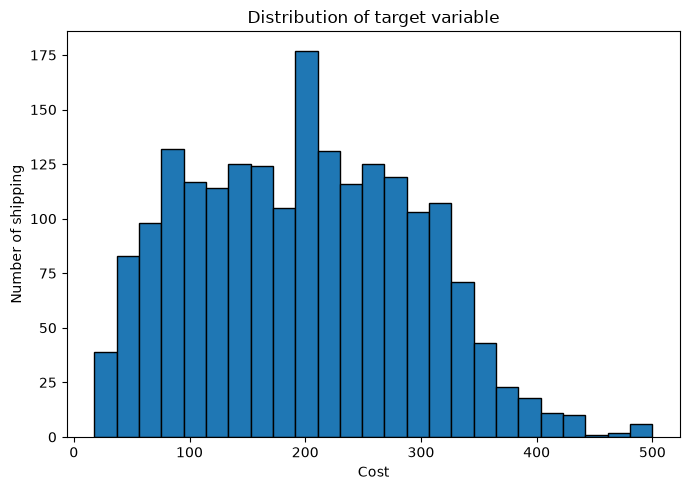

In [33]:
plt.figure(figsize=(7, 5))
plt.hist(y, bins=25, edgecolor="black")
plt.xlabel("Cost")
plt.ylabel("Number of shipping")
plt.title("Distribution of target variable")
plt.tight_layout()
plt.show()

In [34]:
numeric_features = ["Distance_miles","Weight_kg"]
categorical_features = ["Origin_Warehouse", "Destination","Carrier"]
all_features = numeric_features + categorical_features
X = df_clean[all_features]

X.head()

,Distance_miles,Weight_kg,Origin_Warehouse,Destination,Carrier
0,291,25.700,Warehouse_MIA,San Francisco,UPS
1,1225,38.900,Warehouse_MIA,Atlanta,DHL
2,220,37.200,Warehouse_LA,Houston,DHL
3,1156,42.600,Warehouse_BOS,Seattle,OnTrac
4,1017,7.900,Warehouse_SF,Dallas,OnTrac


In [35]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
)

print("Training rows:", X_train.shape[0])
print("Test rows:", X_test.shape[0])

Training rows: 1500
Test rows: 500


In [36]:
try:
    one_hot = OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)
except TypeError:
    one_hot = OneHotEncoder(drop="first", handle_unknown="ignore", sparse=False)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", one_hot),
])

preprocess = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features),
    ]
)

In [37]:
model = Pipeline(steps=[
    ("preprocess", preprocess),
    ("linear_regression", LinearRegression()),
])
model.fit(X_train, y_train)

print("Model fitted successfully.")

Model fitted successfully.


In [38]:
y_pred = model.predict(X_test)

prediction_preview = pd.DataFrame({
    "actual_cost": y_test.values,
    "predicted_cost": y_pred,
    })
prediction_preview["residual"] = prediction_preview["actual_cost"] - prediction_preview["predicted_cost"]

prediction_preview.head()

,actual_cost,predicted_cost,residual
0,196.440,191.915,4.525
1,287.660,292.178,-4.518
2,67.940,86.156,-18.216
3,192.190,176.372,15.818
4,40.650,63.772,-23.122


In [39]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

metrics = pd.DataFrame({
    "metric": ["MAE", "RMSE", "R-squared"],
    "value": [mae, rmse, r2],
})

metrics

,metric,value
0,MAE,28.170
1,RMSE,41.522
2,R-squared,0.820


In [40]:
print(f"MAE interpretation: The model is off by about ${mae:,.2f} on average.")
print(f"RMSE interpretation: After penalizing larger errors more strongly, the typical error is about ${rmse:,.2f}.")
print(f"R-squared interpretation: The model explains about {100*r2:,.1f}% of the variation in the cost of shipping method.")

MAE interpretation: The model is off by about $28.17 on average.
RMSE interpretation: After penalizing larger errors more strongly, the typical error is about $41.52.
R-squared interpretation: The model explains about 82.0% of the variation in the cost of shipping method.


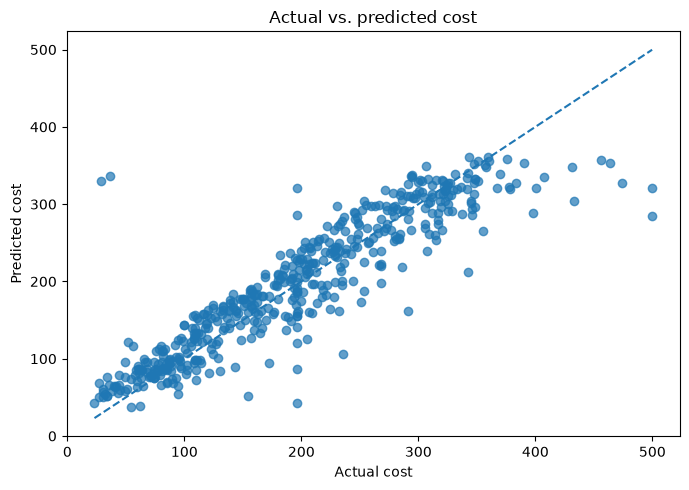

In [41]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.7)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")

plt.xlabel("Actual cost")
plt.ylabel("Predicted cost")
plt.title("Actual vs. predicted cost")
plt.tight_layout()

plt.show()

In [42]:
feature_names = model.named_steps["preprocess"].get_feature_names_out()
clean_feature_names = (
    pd.Series(feature_names)
    .str.replace("numeric__", "", regex=False)
    .str.replace("categorical__", "", regex=False)
)

coefficients = model.named_steps["linear_regression"].coef_
intercept = model.named_steps["linear_regression"].intercept_

coef_df = pd.DataFrame({
    "feature": clean_feature_names,
    "coefficient": coefficients,
})
coef_df["absolute_coefficient"] = coef_df["coefficient"].abs()
coef_df = coef_df.sort_values("absolute_coefficient", ascending=False)

print(f"Intercept: {intercept:,.2f}")
coef_df

Intercept: 27.83


,feature,coefficient,absolute_coefficient
25,Carrier_DHL,29.239,29.239
26,Carrier_FedEx,20.923,20.923
29,Carrier_UPS,10.170,10.170
2,Origin_Warehouse_Warehouse_BOS,-9.082,9.082
12,Destination_Chicago,7.665,7.665
11,Destination_Boston,6.969,6.969
6,Origin_Warehouse_Warehouse_LA,5.676,5.676
27,Carrier_LaserShip,5.486,5.486
22,Destination_Portland,5.112,5.112
21,Destination_Phoenix,4.969,4.969


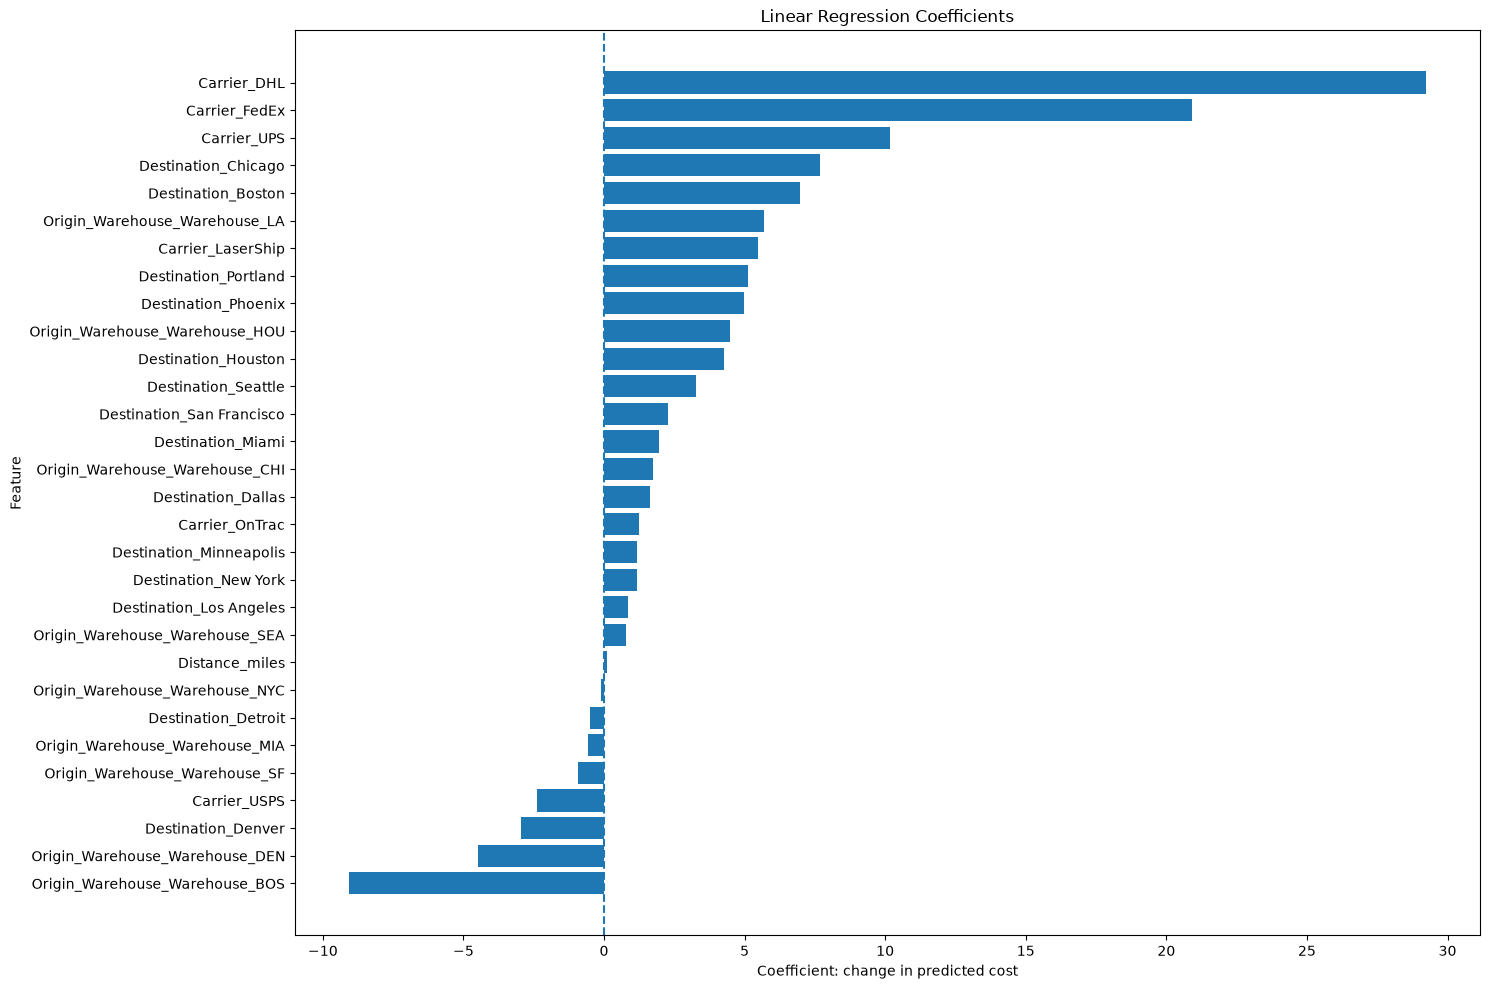

In [43]:
top_coef = coef_df.head(30).sort_values("coefficient")

plt.figure(figsize=(15, 10))
plt.barh(top_coef["feature"], top_coef["coefficient"])
plt.axvline(0, linestyle="--")
plt.title("Linear Regression Coefficients")
plt.xlabel("Coefficient: change in predicted cost")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [44]:
results = X_test.copy()
results["actual_cost"] = y_test.values
results["predicted_cost"] = y_pred
results["residual"] = results["actual_cost"] - results["predicted_cost"]
results["absolute_error"] = results["residual"].abs()

results.head()

,Distance_miles,Weight_kg,Origin_Warehouse,Destination,Carrier,actual_cost,predicted_cost,residual,absolute_error
1860,1323,43.400,Warehouse_SF,Dallas,USPS,196.440,191.915,4.525,4.525
353,2065,34.300,Warehouse_HOU,Minneapolis,OnTrac,287.660,292.178,-4.518,4.518
1333,435,9.000,Warehouse_CHI,San Francisco,Amazon Logistics,67.940,86.156,-18.216,18.216
905,1118,59.400,Warehouse_HOU,Miami,OnTrac,192.190,176.372,15.818,15.818
1289,188,10.300,Warehouse_SF,Chicago,LaserShip,40.650,63.772,-23.122,23.122


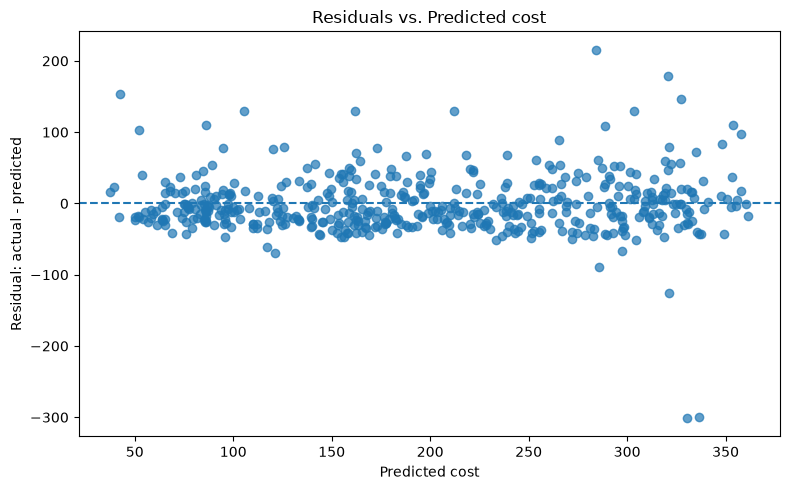

In [45]:
plt.figure(figsize=(8, 5))
plt.scatter(results["predicted_cost"], results["residual"], alpha=0.7)
plt.axhline(0, linestyle="--")
plt.title("Residuals vs. Predicted cost")
plt.xlabel("Predicted cost")
plt.ylabel("Residual: actual - predicted")
plt.tight_layout()
plt.show()

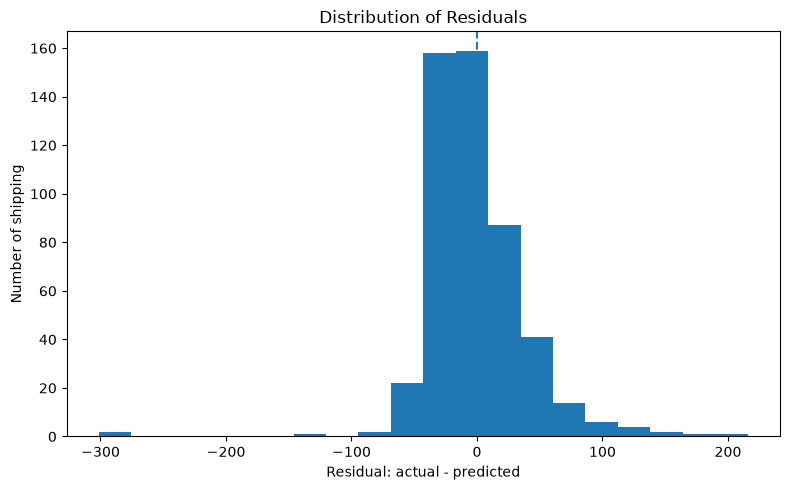

In [46]:
plt.figure(figsize=(8, 5))
plt.hist(results["residual"], bins=20)
plt.axvline(0, linestyle="--")
plt.title("Distribution of Residuals")
plt.xlabel("Residual: actual - predicted")
plt.ylabel("Number of shipping")
plt.tight_layout()
plt.show()

**Random Forest**

In [47]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

# Then split the remaining development data into training and validation sets.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.25,  # 25% of the 80% development set = 20% of the full dataset
    random_state=42,
)

split_sizes = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "rows": [len(X_train), len(X_val), len(X_test)],
})
split_sizes["percent_of_full_data"] = (split_sizes["rows"] / len(X) * 100).round(1)
split_sizes.to_csv(OUTPUT_DIR / "validation_set_sizes.csv", index=False)
split_sizes

,split,rows,percent_of_full_data
0,train,1200,60.000
1,validation,400,20.000
2,test,400,20.000


In [48]:
def make_encoder():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)


def make_preprocess():
    return ColumnTransformer(
        transformers=[
            ("num", "passthrough", numeric_features),
            ("cat", make_encoder(), categorical_features),
        ]
    )

In [49]:
def evaluate_predictions(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }


def fit_and_evaluate(name, model, X_fit, y_fit, X_eval, y_eval, eval_split_name):
    model.fit(X_fit, y_fit)
    train_pred = model.predict(X_fit)
    eval_pred = model.predict(X_eval)

    train_metrics = evaluate_predictions(y_fit, train_pred)
    eval_metrics = evaluate_predictions(y_eval, eval_pred)

    return {
        "model": name,
        "evaluation_split": eval_split_name,
        "train_MAE": train_metrics["MAE"],
        f"{eval_split_name}_MAE": eval_metrics["MAE"],
        "train_RMSE": train_metrics["RMSE"],
        f"{eval_split_name}_RMSE": eval_metrics["RMSE"],
        "train_R2": train_metrics["R2"],
        f"{eval_split_name}_R2": eval_metrics["R2"],
    }

In [50]:
rf_parameter_options = [
    {"n_estimators": 50, "max_depth": 3, "min_samples_leaf": 5},
    {"n_estimators": 100, "max_depth": 3, "min_samples_leaf": 5},
    {"n_estimators": 100, "max_depth": 5, "min_samples_leaf": 5},
    {"n_estimators": 100, "max_depth": None, "min_samples_leaf": 5},
    {"n_estimators": 200, "max_depth": None, "min_samples_leaf": 5},
    {"n_estimators": 200, "max_depth": None, "min_samples_leaf": 1},
]

validation_tuning_rows = []
validation_rf_models = []

for params in rf_parameter_options:
    rf_pipeline = Pipeline(steps=[
        ("preprocess", make_preprocess()),
        ("model", RandomForestRegressor(random_state=42, **params)),
    ])
    rf_pipeline.fit(X_train, y_train)

    train_pred = rf_pipeline.predict(X_train)
    val_pred = rf_pipeline.predict(X_val)

    train_metrics = evaluate_predictions(y_train, train_pred)
    val_metrics = evaluate_predictions(y_val, val_pred)

    row = {
        **params,
        "train_MAE": train_metrics["MAE"],
        "validation_MAE": val_metrics["MAE"],
        "train_RMSE": train_metrics["RMSE"],
        "validation_RMSE": val_metrics["RMSE"],
        "validation_R2": val_metrics["R2"],
    }
    validation_tuning_rows.append(row)
    validation_rf_models.append((params, rf_pipeline, row))

rf_validation_tuning = pd.DataFrame(validation_tuning_rows).sort_values("validation_RMSE")
rf_validation_tuning

,n_estimators,max_depth,min_samples_leaf,train_MAE,validation_MAE,train_RMSE,validation_RMSE,validation_R2
4,200,NaN,5,15.111,18.958,24.200,36.619,0.843
3,100,NaN,5,15.111,18.933,24.175,36.672,0.842
2,100,5.000,5,18.741,20.449,28.315,37.529,0.835
5,200,NaN,1,7.627,19.483,12.036,37.533,0.835
1,100,3.000,5,24.740,24.684,34.804,39.800,0.814
0,50,3.000,5,24.940,24.922,34.954,40.007,0.812


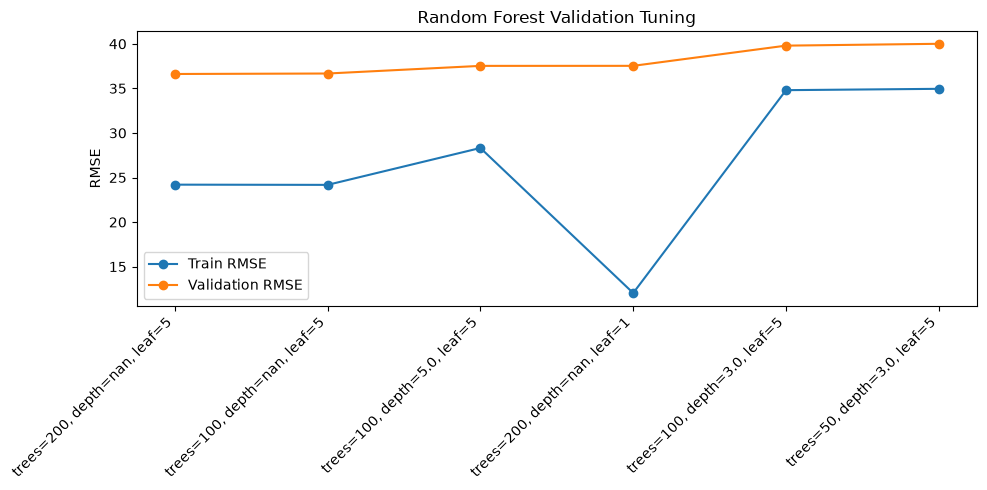

In [55]:
plot_tuning = rf_validation_tuning.copy()
plot_tuning["model_label"] = [
    f"trees={r.n_estimators}, depth={r.max_depth}, leaf={r.min_samples_leaf}"
    for r in plot_tuning.itertuples()
]

plt.figure(figsize=(10, 5))
plt.plot(plot_tuning["model_label"], plot_tuning["train_RMSE"], marker="o", label="Train RMSE")
plt.plot(plot_tuning["model_label"], plot_tuning["validation_RMSE"], marker="o", label="Validation RMSE")
plt.xticks(rotation=45, ha="right")
plt.ylabel("RMSE")
plt.title("Random Forest Validation Tuning")
plt.legend()
plt.tight_layout()
plt.show()

In [54]:
best_validation_row = rf_validation_tuning.iloc[0]
best_params = {
    "n_estimators": int(best_validation_row["n_estimators"]),
    "max_depth": None if pd.isna(best_validation_row["max_depth"]) else int(best_validation_row["max_depth"]),
    "min_samples_leaf": int(best_validation_row["min_samples_leaf"]),
}

print("Best validation parameters:")
print(best_params)

best_validation_rf = Pipeline(steps=[
    ("preprocess", make_preprocess()),
    ("model", RandomForestRegressor(random_state=42, **best_params)),
])
best_validation_rf.fit(X_train, y_train)

Best validation parameters:
{'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 5}


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['Distance_miles','Weight_kg','Origin_Warehouse','Destination','Carrier']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis

In [56]:
feature_names = best_validation_rf.named_steps["preprocess"].get_feature_names_out()
rf_model = best_validation_rf.named_steps["model"]

built_in_importance = pd.DataFrame({
    "encoded_feature": feature_names,
    "built_in_feature_importance": rf_model.feature_importances_,
})

built_in_importance["feature_clean"] = (
    built_in_importance["encoded_feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
)

built_in_importance = built_in_importance.sort_values("built_in_feature_importance", ascending=False)
built_in_importance.to_csv(OUTPUT_DIR / "week7_feature_importances.csv", index=False)
built_in_importance.head(12)

,encoded_feature,built_in_feature_importance,feature_clean
0,num__Distance_miles,0.902,Distance_miles
1,num__Weight_kg,0.080,Weight_kg
28,cat__Carrier_DHL,0.004,Carrier_DHL
33,cat__Carrier_USPS,0.004,Carrier_USPS
29,cat__Carrier_FedEx,0.003,Carrier_FedEx
31,cat__Carrier_OnTrac,0.001,Carrier_OnTrac
32,cat__Carrier_UPS,0.001,Carrier_UPS
30,cat__Carrier_LaserShip,0.001,Carrier_LaserShip
27,cat__Carrier_Amazon Logistics,0.001,Carrier_Amazon Logistics
6,cat__Origin_Warehouse_Warehouse_HOU,0.001,Origin_Warehouse_Warehouse_HOU


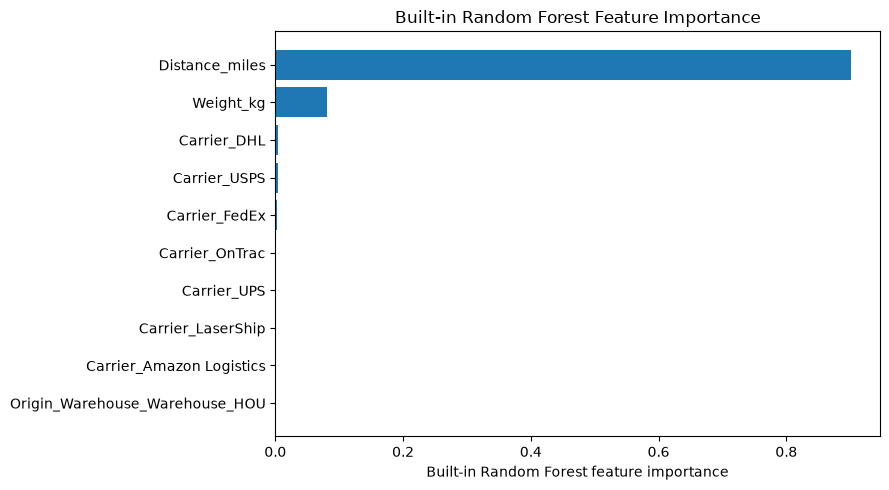

In [60]:
top_importance = built_in_importance.head(10).sort_values("built_in_feature_importance")

plt.figure(figsize=(9, 5))
plt.barh(top_importance["feature_clean"], top_importance["built_in_feature_importance"])
plt.xlabel("Built-in Random Forest feature importance")
plt.title("Built-in Random Forest Feature Importance")
plt.tight_layout()
plt.show()

In [61]:
perm = permutation_importance(
    best_validation_rf,
    X_val,
    y_val,
    n_repeats=20,
    random_state=42,
    scoring="neg_mean_absolute_error",
)

permutation_table = pd.DataFrame({
    "feature": X_val.columns,
    "permutation_importance_MAE_increase": perm.importances_mean,
    "importance_std": perm.importances_std,
}).sort_values("permutation_importance_MAE_increase", ascending=False)

permutation_table.to_csv(OUTPUT_DIR / "week7_permutation_importance.csv", index=False)
permutation_table

,feature,permutation_importance_MAE_increase,importance_std
0,Distance_miles,79.651,3.314
1,Weight_kg,14.614,0.655
4,Carrier,2.338,0.299
2,Origin_Warehouse,0.054,0.044
3,Destination,-0.001,0.041


In [62]:
# Aggregate built-in importance back to original feature families.
importance_family = built_in_importance.copy()
importance_family["original_feature_family"] = importance_family["feature_clean"].str.split("_").str[0]

# More explicit mapping for one-hot columns.
def original_feature_name(encoded_name):
    clean = encoded_name.replace("num__", "").replace("cat__", "")
    for col in numeric_features + categorical_features:
        if clean == col or clean.startswith(col + "_"):
            return col
    return clean

importance_family["original_feature"] = importance_family["encoded_feature"].apply(original_feature_name)

built_in_by_original = (
    importance_family.groupby("original_feature", as_index=False)["built_in_feature_importance"]
    .sum()
)

importance_comparison = built_in_by_original.merge(
    permutation_table,
    left_on="original_feature",
    right_on="feature",
    how="outer",
).drop(columns=["feature"])

importance_comparison = importance_comparison.sort_values(
    "permutation_importance_MAE_increase",
    ascending=False,
)
importance_comparison.to_csv(OUTPUT_DIR / "week7_importance_method_comparison.csv", index=False)
importance_comparison

,original_feature,built_in_feature_importance,permutation_importance_MAE_increase,importance_std
2,Distance_miles,0.902,79.651,3.314
4,Weight_kg,0.080,14.614,0.655
0,Carrier,0.014,2.338,0.299
3,Origin_Warehouse,0.002,0.054,0.044
1,Destination,0.002,-0.001,0.041


In [67]:
final_random_forest = Pipeline(steps=[
    ("preprocess", make_preprocess()),
    ("model", RandomForestRegressor(random_state=42, **best_params)),
])

final_linear_regression = Pipeline(steps=[
    ("preprocess", make_preprocess()),
    ("model", LinearRegression()),
])

mean_baseline = DummyRegressor(strategy="mean")
median_baseline = DummyRegressor(strategy="median")

final_models = {
    "Mean baseline": mean_baseline,
    "Median baseline": median_baseline,
    "Linear Regression": final_linear_regression,
    "Final Random Forest": final_random_forest,
}

test_rows = []
for name, model in final_models.items():
    test_rows.append(
        fit_and_evaluate(name, model, X_train_full, y_train_full, X_test, y_test, "test")
    )

final_test_comparison = pd.DataFrame(test_rows).sort_values("test_RMSE")
final_test_comparison.to_csv(OUTPUT_DIR / "week7_final_model_comparison.csv", index=False)
final_test_comparison

,model,evaluation_split,train_MAE,test_MAE,train_RMSE,test_RMSE,train_R2,test_R2
3,Final Random Forest,test,14.596,21.137,25.213,35.657,0.929,0.868
2,Linear Regression,test,26.427,27.026,38.903,39.340,0.832,0.840
1,Median baseline,test,79.207,81.394,94.997,98.261,-0.001,-0.001
0,Mean baseline,test,79.260,81.694,94.940,98.426,0.000,-0.004


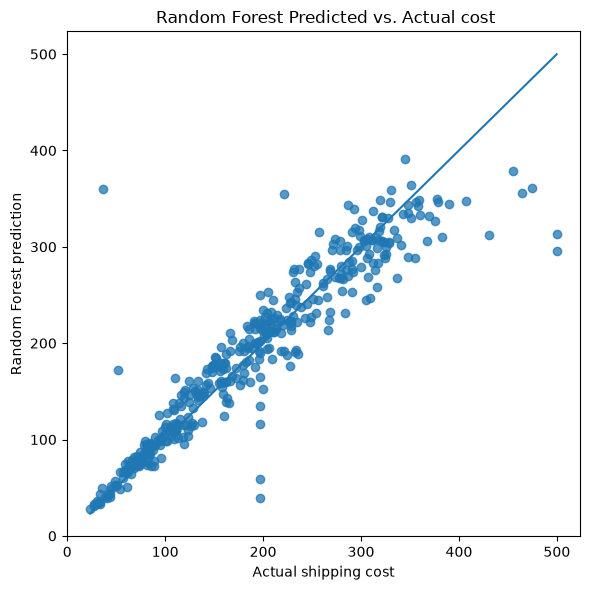

In [59]:
linear_pred = final_linear_regression.predict(X_test)
rf_pred = final_random_forest.predict(X_test)
plt.figure(figsize=(6, 6))
plt.scatter(y_test, rf_pred, alpha=0.75)
min_value = min(float(y_test.min()), float(rf_pred.min()))
max_value = max(float(y_test.max()), float(rf_pred.max()))
plt.plot([min_value, max_value], [min_value, max_value])
plt.xlabel("Actual shipping cost")
plt.ylabel("Random Forest prediction")
plt.title(" Random Forest Predicted vs. Actual cost")
plt.tight_layout()
plt.show()